# 4. Mô hình hóa và đánh giá

Notebook 1–3 đã biến dữ liệu bẩn thành `credit_clean.csv` / `credit_features.csv`. Notebook này trả lời:

1. **Làm sạch đóng góp bao nhiêu cho mô hình?** (thí nghiệm *ablation* theo từng bước làm sạch – trọng tâm của bài)
2. Mô hình nào tốt nhất, tối ưu siêu tham số và xử lý lệch lớp ra sao?
3. Kết quả cuối cùng trên tập kiểm tra *chưa từng đụng tới*, mô hình dựa vào đặc trưng nào, sai ở đâu?

## Quy trình đánh giá (thiết kế để kết quả đáng tin)
| Vấn đề | Cách xử lý |
|---|---|
| Mỗi khách có 8 dòng giống nhau → chia ngẫu nhiên theo dòng sẽ **rò rỉ** (cùng người ở cả train và test) | **Chia theo khách hàng** (`GroupShuffleSplit` cho tập kiểm tra; `StratifiedGroupKFold` cho CV) |
| Nhãn lệch lớp (Standard 53%, Good 18%) | Chỉ số chính là **macro-F1** (trung bình F1 ba lớp); báo thêm accuracy và recall từng lớp |
| Chọn mô hình / siêu tham số mà nhìn vào tập kiểm tra → lạc quan giả | Tập kiểm tra (20% khách) **chỉ dùng một lần ở cuối**; mọi lựa chọn dùng CV trên 80% còn lại |
| Một lần chạy có thể may rủi | CV 5 phần, báo **trung bình ± độ lệch chuẩn** giữa các phần; khoảng tin cậy bootstrap theo khách ở kết quả cuối |
| Đường cơ sở | Đoán lớp phổ biến (Standard) → accuracy ≈ 53% |

In [1]:
import sys, json, time, warnings
sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Markdown, display
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, RandomizedSearchCV
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report, roc_auc_score, log_loss, precision_recall_fscore_support
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
import credit_cleaning as cc, credit_features as cf
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
pd.set_option('display.max_columns', 50); pd.set_option('display.width', 170)
ORDER = ['Poor', 'Standard', 'Good']; PAL = {'Poor': '#c0392b', 'Standard': '#f39c12', 'Good': '#27ae60'}
os_makedirs = __import__('os').makedirs; os_makedirs('../data/reports', exist_ok=True)
T0 = time.time()

raw = pd.read_csv('../data/train.csv', low_memory=False)
clean = pd.read_csv('../data/credit_clean.csv')
feat = pd.read_csv('../data/credit_features.csv')
assert len(raw) == len(clean) == len(feat) and (raw.ID.values == clean.ID.values).all() and (clean.ID.values == feat.ID.values).all()
y_all = clean['Credit_Score']; groups_all = clean['Customer_ID']
print(raw.shape, clean.shape, feat.shape)

(100000, 28) (100000, 29) (100000, 74)


## 4.1 Chia dữ liệu theo khách hàng
20% khách hàng (2.500 người, toàn bộ 8 tháng của họ) làm **tập kiểm tra giữ kín**; 80% còn lại (10.000 khách) dùng cho mọi thí nghiệm bằng CV 5 phần.

In [2]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
tr_idx, te_idx = next(gss.split(clean, y_all, groups_all))
ytr, yte = y_all.iloc[tr_idx].reset_index(drop=True), y_all.iloc[te_idx].reset_index(drop=True)
gtr, gte = groups_all.iloc[tr_idx].reset_index(drop=True), groups_all.iloc[te_idx].reset_index(drop=True)
assert set(gtr).isdisjoint(set(gte))
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
folds = list(cv.split(np.zeros(len(ytr)), ytr, gtr))
print(f'Train: {len(tr_idx):,} dòng / {gtr.nunique():,} khách | Test giữ kín: {len(te_idx):,} dòng / {gte.nunique():,} khách | không trùng khách ✓')
print(pd.DataFrame({'train': ytr.value_counts(normalize=True), 'test': yte.value_counts(normalize=True)}).reindex(ORDER).round(3).T.to_string())
print('Đường cơ sở (luôn đoán Standard): accuracy test =', round((yte == 'Standard').mean(), 3))

Train: 80,000 dòng / 10,000 khách | Test giữ kín: 20,000 dòng / 2,500 khách | không trùng khách ✓
Credit_Score   Poor  Standard   Good
train         0.291     0.532  0.177
test          0.286     0.529  0.185
Đường cơ sở (luôn đoán Standard): accuracy test = 0.529


In [3]:
def cv_eval(make_model, X, folds=folds, y=ytr):
    # trả về mảng (số phần × 2): accuracy, macro-F1 trên từng phần CV
    out = []
    for tr, va in folds:
        m = make_model().fit(X.iloc[tr], y.iloc[tr]); p = m.predict(X.iloc[va])
        out.append((accuracy_score(y.iloc[va], p), f1_score(y.iloc[va], p, average='macro')))
    return np.array(out)

MODELS = {
    'Logistic Regression': lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    'Random Forest':       lambda: RandomForestClassifier(n_estimators=150, min_samples_leaf=2, n_jobs=2, random_state=0),
    'HistGradientBoosting': lambda: HistGradientBoostingClassifier(max_iter=200, random_state=0),
}
def fmt(a): return f'{a.mean():.3f} ± {a.std():.3f}'

## 4.2 Thí nghiệm trọng tâm: làm sạch đóng góp bao nhiêu? (ablation)

Cùng một bộ cột (`BASE`: 17 cột số + 4 cột phân loại), cùng mô hình, cùng các phần CV – **chỉ khác mức độ làm sạch**, cộng dần từng bước của pipeline:

| Giai đoạn | Mô tả | Giống cách làm của người "tải về là chạy" |
|---|---|---|
| **S0 – Thô** | chỉ bỏ dấu `_` và ép số; placeholder **còn nguyên** (`__10000__` → 10000, `-3·10²⁶`, `Credit_Mix='_'`...); ô thiếu điền trung vị/mode toàn cục | ✔ |
| **S1 – Bỏ placeholder** | S0 + giá trị giả → NaN, rồi điền toàn cục | |
| **S2 – Bỏ giá trị vô lý** | S1 + loại giá trị ngoài miền hợp lệ, rồi điền toàn cục | |
| **S3 – Làm sạch đầy đủ** | S2 + điền theo khách / chiến lược đã kiểm chứng (= `credit_clean.csv`) | |
| `S2*` | *S2 nhưng không điền, để `HistGradientBoosting` tự xử lý NaN* | *đối chứng: "để mô hình lo"* |

In [4]:
def global_fill(d, num, cat):
    d = d.copy()
    for c in num: d[c] = d[c].fillna(d[c].median())
    for c in cat: d[c] = d[c].fillna(d[c].mode().iloc[0])
    return d

def design(d, fill=True):
    num, cat = cf.BASE_NUM, cf.BASE_CAT
    d = global_fill(d, num, cat) if fill else d
    return pd.get_dummies(d[num + cat], columns=cat, dtype=float)

base = cc.add_month_num(raw)
parse_hist = lambda d: d.assign(Credit_History_Months=d['Credit_History_Age'].map(cc.parse_history_months))

s0 = parse_hist(cc.strip_numeric_text(base))                                         # S0: thô
s1 = parse_hist(cc.strip_numeric_text(cc.mark_placeholders(base)))                   # S1: + placeholder -> NaN
s2 = cc.mark_invalid(s1.copy())                                                      # S2: + giá trị vô lý -> NaN
STAGES = {'S0 – Thô': design(s0), 'S1 – Bỏ placeholder': design(s1), 'S2 – Bỏ giá trị vô lý': design(s2),
          'S3 – Làm sạch đầy đủ': design(clean)}
STAGES = {k: v.iloc[tr_idx].reset_index(drop=True) for k, v in STAGES.items()}
X_s2_nan = pd.get_dummies(s2[cf.BASE_NUM + cf.BASE_CAT], columns=cf.BASE_CAT, dtype=float).iloc[tr_idx].reset_index(drop=True)   # S2*: giữ NaN
for k, v in STAGES.items(): print(f'{k:26s} {v.shape}  NaN còn lại: {int(v.isna().sum().sum())}')

S0 – Thô                   (80000, 47)  NaN còn lại: 0
S1 – Bỏ placeholder        (80000, 44)  NaN còn lại: 0
S2 – Bỏ giá trị vô lý      (80000, 44)  NaN còn lại: 0
S3 – Làm sạch đầy đủ       (80000, 45)  NaN còn lại: 0


In [5]:
abl_rows = []
for model_name, mk in MODELS.items():
    for stage, X in STAGES.items():
        t = time.time(); r = cv_eval(mk, X)
        abl_rows.append({'mô hình': model_name, 'giai đoạn': stage, 'acc': r[:, 0].mean(), 'acc_sd': r[:, 0].std(), 'f1': r[:, 1].mean(), 'f1_sd': r[:, 1].std(), 'f1_folds': r[:, 1].round(5).tolist()})
        print(f'{model_name:22s} {stage:26s} macro-F1 {r[:, 1].mean():.4f} ± {r[:, 1].std():.4f}   ({time.time() - t:.0f}s)', flush=True)
r = cv_eval(MODELS['HistGradientBoosting'], X_s2_nan)
abl_rows.append({'mô hình': 'HistGradientBoosting', 'giai đoạn': 'S2* – Vô lý→NaN, mô hình tự xử lý NaN', 'acc': r[:, 0].mean(), 'acc_sd': r[:, 0].std(), 'f1': r[:, 1].mean(), 'f1_sd': r[:, 1].std(), 'f1_folds': r[:, 1].round(5).tolist()})
abl = pd.DataFrame(abl_rows); abl.to_csv('../data/reports/ablation_cleaning.csv', index=False)
print(f'S2* HGB tự xử lý NaN: macro-F1 {r[:, 1].mean():.4f} ± {r[:, 1].std():.4f}')

Logistic Regression    S0 – Thô                   macro-F1 0.5888 ± 0.0054   (4s)


Logistic Regression    S1 – Bỏ placeholder        macro-F1 0.5846 ± 0.0065   (4s)


Logistic Regression    S2 – Bỏ giá trị vô lý      macro-F1 0.6116 ± 0.0057   (8s)


Logistic Regression    S3 – Làm sạch đầy đủ       macro-F1 0.6393 ± 0.0065   (15s)


Random Forest          S0 – Thô                   macro-F1 0.6690 ± 0.0018   (52s)


...

HistGradientBoosting   S0 – Thô                   macro-F1 0.6621 ± 0.0052   (38s)


HistGradientBoosting   S1 – Bỏ placeholder        macro-F1 0.6599 ± 0.0045   (36s)


HistGradientBoosting   S2 – Bỏ giá trị vô lý      macro-F1 0.6572 ± 0.0017   (35s)


HistGradientBoosting   S3 – Làm sạch đầy đủ       macro-F1 0.6712 ± 0.0035   (38s)


S2* HGB tự xử lý NaN: macro-F1 0.6634 ± 0.0040


mô hình,HistGradientBoosting,Logistic Regression,Random Forest
giai đoạn,,,
S0 – Thô,0.662 ± 0.005,0.589 ± 0.005,0.669 ± 0.002
S1 – Bỏ placeholder,0.660 ± 0.005,0.585 ± 0.006,0.667 ± 0.004
S2 – Bỏ giá trị vô lý,0.657 ± 0.002,0.612 ± 0.006,0.667 ± 0.002
"S2* – Vô lý→NaN, mô hình tự xử lý NaN",0.663 ± 0.004,NaN,NaN
S3 – Làm sạch đầy đủ,0.671 ± 0.004,0.639 ± 0.006,0.679 ± 0.001


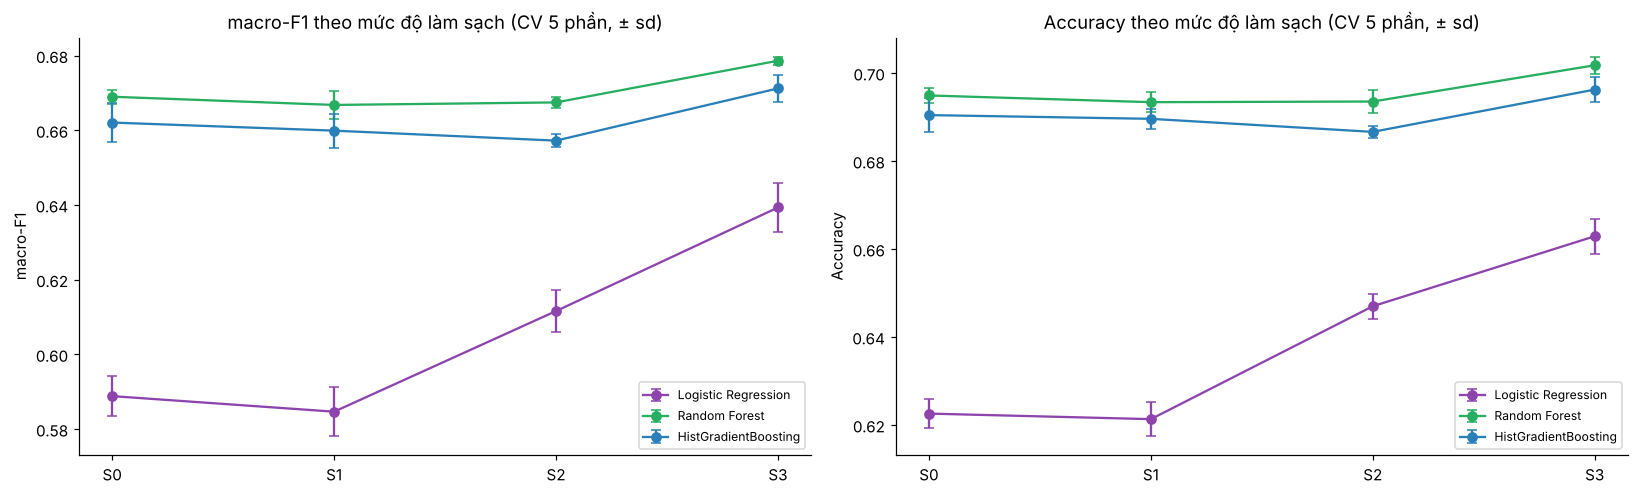

In [6]:
tab = abl.assign(**{'accuracy': abl.acc.map('{:.3f}'.format) + ' ± ' + abl.acc_sd.map('{:.3f}'.format),
                    'macro-F1': abl.f1.map('{:.3f}'.format) + ' ± ' + abl.f1_sd.map('{:.3f}'.format)})
display(tab.pivot(index='giai đoạn', columns='mô hình', values='macro-F1'))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
stg = ['S0 – Thô', 'S1 – Bỏ placeholder', 'S2 – Bỏ giá trị vô lý', 'S3 – Làm sạch đầy đủ']; cols = {'Logistic Regression': '#8e44ad', 'Random Forest': '#27ae60', 'HistGradientBoosting': '#2980b9'}
for a, (met, sd, ttl) in zip(ax, [('f1', 'f1_sd', 'macro-F1'), ('acc', 'acc_sd', 'Accuracy')]):
    for m, c in cols.items():
        s = abl[(abl['mô hình'] == m) & abl['giai đoạn'].isin(stg)].set_index('giai đoạn').loc[stg]
        a.errorbar(range(4), s[met], yerr=s[sd], marker='o', color=c, label=m, capsize=3)
    a.set_xticks(range(4)); a.set_xticklabels([x.split(' – ')[0] for x in stg]); a.set_ylabel(ttl); a.set_title(f'{ttl} theo mức độ làm sạch (CV 5 phần, ± sd)'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [7]:
g = abl.set_index(['mô hình', 'giai đoạn'])
lines = []
for m in cols:
    f0, f3 = g.loc[(m, stg[0]), 'f1'], g.loc[(m, stg[3]), 'f1']; a0, a3 = g.loc[(m, stg[0]), 'acc'], g.loc[(m, stg[3]), 'acc']
    lines.append(f'- **{m}**: macro-F1 {f0:.3f} → {f3:.3f} (**{(f3 - f0) * 100:+.1f} điểm %**); accuracy {a0:.3f} → {a3:.3f} ({(a3 - a0) * 100:+.1f} điểm %)')
hgb = 'HistGradientBoosting'; star = g.loc[(hgb, 'S2* – Vô lý→NaN, mô hình tự xử lý NaN'), 'f1']
lines.append(f'- Đối chứng: để HistGradientBoosting **tự xử lý NaN** (S2*) cho macro-F1 {star:.3f}, so với {g.loc[(hgb, stg[3]), "f1"]:.3f} khi làm sạch đầy đủ (S3) và {g.loc[(hgb, stg[0]), "f1"]:.3f} khi dữ liệu thô (S0).')
display(Markdown('**Tóm tắt ablation (macro-F1 trên CV):**\n\n' + '\n'.join(lines)))

**Tóm tắt ablation (macro-F1 trên CV):**

- **Logistic Regression**: macro-F1 0.589 → 0.639 (**+5.1 điểm %**); accuracy 0.623 → 0.663 (+4.0 điểm %)
- **Random Forest**: macro-F1 0.669 → 0.679 (**+1.0 điểm %**); accuracy 0.695 → 0.702 (+0.7 điểm %)
- **HistGradientBoosting**: macro-F1 0.662 → 0.671 (**+0.9 điểm %**); accuracy 0.690 → 0.696 (+0.6 điểm %)
- Đối chứng: để HistGradientBoosting **tự xử lý NaN** (S2*) cho macro-F1 0.663, so với 0.671 khi làm sạch đầy đủ (S3) và 0.662 khi dữ liệu thô (S0).

In [8]:
# Chênh lệch GHÉP CẶP trên từng phần CV (cùng khách, cùng phần) – cho biết cải thiện có nhất quán hay chỉ là nhiễu
def fold_f1(m, st): return np.array(g.loc[(m, st), 'f1_folds'])
rows = []
for m in cols:
    for a_, b_ in [(stg[3], stg[0]), (stg[3], stg[2])] + ([(stg[3], 'S2* – Vô lý→NaN, mô hình tự xử lý NaN')] if m == hgb else []):
        d_ = fold_f1(m, a_) - fold_f1(m, b_)
        rows.append({'mô hình': m, 'so sánh': a_.split(' – ')[0] + ' − ' + b_.split(' – ')[0], 'Δ macro-F1 TB (điểm %)': d_.mean() * 100,
                     'Δ nhỏ nhất (điểm %)': d_.min() * 100, 'số phần cải thiện': f'{int((d_ > 0).sum())}/{len(d_)}'})
paired = pd.DataFrame(rows).set_index(['mô hình', 'so sánh']); paired.round(2)

Δ macro-F1 TB (điểm %)  Δ nhỏ nhất (điểm %) số phần cải thiện
mô hình              so sánh                                                                
Logistic Regression  S3 − S0                     5.05                 4.22               5/5
                     S3 − S2                     2.77                 2.48               5/5
Random Forest        S3 − S0                     0.96                 0.75               5/5
                     S3 − S2                     1.12                 0.91               5/5
HistGradientBoosting S3 − S0                     0.91                 0.06               5/5
                     S3 − S2                     1.40                 1.02               5/5
                     S3 − S2*                    0.78                 0.33               5/5

In [9]:
trees = ['Random Forest', 'HistGradientBoosting']
def mid_vs_s0(m): return [g.loc[(m, s_), 'f1'] - g.loc[(m, stg[0]), 'f1'] for s_ in stg[1:3]]
lr_gain = paired.loc[('Logistic Regression', 'S3 − S0'), 'Δ macro-F1 TB (điểm %)']
tree_gain = [paired.loc[(m, 'S3 − S0'), 'Δ macro-F1 TB (điểm %)'] for m in trees]
tree_all = all(paired.loc[(m, 'S3 − S0'), 'số phần cải thiện'].split('/')[0] == paired.loc[(m, 'S3 − S0'), 'số phần cải thiện'].split('/')[1] for m in trees)
consist = 'hơn S0 ở mọi phần CV' if tree_all else 'không hơn S0 ở mọi phần CV (xem cột "số phần cải thiện")'
mid = {m: mid_vs_s0(m) for m in trees}
star_gap = paired.loc[(hgb, 'S3 − S2*'), 'Δ macro-F1 TB (điểm %)']; star_vs_s0 = (g.loc[(hgb, 'S2* – Vô lý→NaN, mô hình tự xử lý NaN'), 'f1'] - g.loc[(hgb, stg[0]), 'f1']) * 100
display(Markdown(f'''**Cách đọc.**
- **S3 (làm sạch đầy đủ) cho macro-F1 cao nhất ở cả ba mô hình.** Mức tăng so với dữ liệu thô: **{lr_gain:+.1f} điểm %** với Logistic Regression, và {tree_gain[0]:+.1f} / {tree_gain[1]:+.1f} điểm % với Random Forest / HistGradientBoosting; ở hai mô hình cây, S3 {consist} so với S0 (bảng ghép cặp ở trên).
- **Mô hình tuyến tính hưởng lợi nhiều nhất**: nó bị phá bởi ngoại lệ cực đoan (một giá trị −3·10²⁶ làm phép chuẩn hóa vô nghĩa), nên ở S0 kém hơn hẳn các mô hình cây. Mô hình cây chịu ngoại lệ tốt hơn (chỉ so sánh thứ tự), nên khoảng cách nhỏ hơn.
- **Làm sạch "máy móc" không đủ.** Với mô hình cây, S1 và S2 (bỏ placeholder / giá trị vô lý rồi điền trung vị toàn cục) đạt chênh lệch so với S0 là {mid['Random Forest'][0] * 100:+.1f}/{mid['Random Forest'][1] * 100:+.1f} (RF) và {mid['HistGradientBoosting'][0] * 100:+.1f}/{mid['HistGradientBoosting'][1] * 100:+.1f} (HGB) điểm % – tức **không hơn dữ liệu thô** (trong phạm vi sai số); một cách giải thích hợp lý (chưa kiểm chứng riêng) là điền *một con số chung* cho hàng nghìn ô thiếu cũng làm méo dữ liệu, gần như không khác giữ giá trị rác. Chỉ khi điền **theo từng khách / theo ràng buộc giữa các cột** (S3) mới thấy lợi ích.
- **"Để mô hình tự lo NaN" (`S2*`) cũng không giúp được** ({star_vs_s0:+.1f} điểm % so với S0), còn S3 hơn `S2*` {star_gap:+.1f} điểm % – vì mô hình không biết rằng ô thiếu của khách này có thể suy ra từ các tháng khác của chính họ.

**Giới hạn cần nói rõ:** đây là bài toán mà mô hình cây đạt macro-F1 chỉ ≈ 0,67–0,68 dù dữ liệu đã sạch, nên "trần" hiệu năng thấp và phần làm sạch đóng góp thêm khoảng 1 điểm % cho mô hình cây (5 điểm % cho mô hình tuyến tính); không nên kỳ vọng làm sạch biến mô hình yếu thành mô hình tốt khi nhãn vốn có nhiễu (xem phân tích lỗi, mục 4.9).'''))

**Cách đọc.**
- **S3 (làm sạch đầy đủ) cho macro-F1 cao nhất ở cả ba mô hình.** Mức tăng so với dữ liệu thô: **+5.1 điểm %** với Logistic Regression, và +1.0 / +0.9 điểm % với Random Forest / HistGradientBoosting; ở hai mô hình cây, S3 hơn S0 ở mọi phần CV so với S0 (bảng ghép cặp ở trên).
- **Mô hình tuyến tính hưởng lợi nhiều nhất**: nó bị phá bởi ngoại lệ cực đoan (một giá trị −3·10²⁶ làm phép chuẩn hóa vô nghĩa), nên ở S0 kém hơn hẳn các mô hình cây. Mô hình cây chịu ngoại lệ tốt hơn (chỉ so sánh thứ tự), nên khoảng cách nhỏ hơn.
- **Làm sạch "máy móc" không đủ.** Với mô hình cây, S1 và S2 (bỏ placeholder / giá trị vô lý rồi điền trung vị toàn cục) đạt chênh lệch so với S0 là -0.2/-0.2 (RF) và -0.2/-0.5 (HGB) điểm % – tức **không hơn dữ liệu thô** (trong phạm vi sai số); một cách giải thích hợp lý (chưa kiểm chứng riêng) là điền *một con số chung* cho hàng nghìn ô thiếu cũng làm méo dữ liệu, gần như không khác giữ giá trị rác. Chỉ khi điền **theo từng khách / theo ràng buộc giữa các cột** (S3) mới thấy lợi ích.
- **"Để mô hình tự lo NaN" (`S2*`) cũng không giúp được** (+0.1 điểm % so với S0), còn S3 hơn `S2*` +0.8 điểm % – vì mô hình không biết rằng ô thiếu của khách này có thể suy ra từ các tháng khác của chính họ.

**Giới hạn cần nói rõ:** đây là bài toán mà mô hình cây đạt macro-F1 chỉ ≈ 0,67–0,68 dù dữ liệu đã sạch, nên "trần" hiệu năng thấp và phần làm sạch đóng góp thêm khoảng 1 điểm % cho mô hình cây (5 điểm % cho mô hình tuyến tính); không nên kỳ vọng làm sạch biến mô hình yếu thành mô hình tốt khi nhãn vốn có nhiễu (xem phân tích lỗi, mục 4.9).

## 4.3 Đặc trưng nào đáng đưa vào? (ablation nhóm đặc trưng)
Trên dữ liệu **sạch**, thêm dần từng nhóm đặc trưng (notebook 3). Mỗi dòng là một bộ đặc trưng; cột *"+ nhóm"* cho biết lợi ích của việc thêm nhóm đó vào bộ trước.

> **Phân biệt quan trọng:** `LAG` chỉ dùng tháng hiện tại và các tháng *trước* → triển khai được thực tế. `CUST_AGG` dùng cả các tháng *sau* → chỉ hợp lệ khi đã có đủ 8 tháng (đánh giá "nhìn lại"). Hai trường hợp được báo cáo **riêng**, không trộn lẫn.

In [10]:
FS = {
    'BASE':                                   ['BASE'],
    '+ RATIO':                                ['BASE', 'RATIO'],
    '+ LOAN':                                 ['BASE', 'RATIO', 'LOAN'],
    '+ PB_SPLIT':                             ['BASE', 'RATIO', 'LOAN', 'PB_SPLIT'],
    '+ LAG  (nhân quả – triển khai được)':    ['BASE', 'RATIO', 'LOAN', 'PB_SPLIT', 'LAG'],
    '+ CUST_AGG  (nhìn lại 8 tháng)':         ['BASE', 'RATIO', 'LOAN', 'PB_SPLIT', 'LAG', 'CUST_AGG'],
}
fs_rows = []
for name, grp in FS.items():
    X = cf.make_matrix(feat, grp).iloc[tr_idx].reset_index(drop=True)
    for mname in ['Logistic Regression', 'HistGradientBoosting']:
        r = cv_eval(MODELS[mname], X)
        fs_rows.append({'bộ đặc trưng': name, 'số cột': X.shape[1], 'mô hình': mname, 'acc': r[:, 0].mean(), 'f1': r[:, 1].mean(), 'f1_sd': r[:, 1].std()})
        print(f'{name:40s} {mname:22s} cols={X.shape[1]:3d} macro-F1 {r[:, 1].mean():.4f} ± {r[:, 1].std():.4f}', flush=True)
fs = pd.DataFrame(fs_rows); fs.to_csv('../data/reports/ablation_features.csv', index=False)
piv = fs.pivot(index='bộ đặc trưng', columns='mô hình', values='f1').loc[list(FS)]
piv['số cột'] = fs.drop_duplicates('bộ đặc trưng').set_index('bộ đặc trưng')['số cột'].loc[list(FS)]
for m in ['Logistic Regression', 'HistGradientBoosting']: piv[f'{m}: Δ so với bộ trước'] = piv[m].diff().round(4)
piv.round(4)

BASE                                     Logistic Regression    cols= 45 macro-F1 0.6394 ± 0.0064


BASE                                     HistGradientBoosting   cols= 45 macro-F1 0.6712 ± 0.0035


+ RATIO                                  Logistic Regression    cols= 52 macro-F1 0.6394 ± 0.0073


+ RATIO                                  HistGradientBoosting   cols= 52 macro-F1 0.6710 ± 0.0055


+ LOAN                                   Logistic Regression    cols= 61 macro-F1 0.6396 ± 0.0076


...

+ LAG  (nhân quả – triển khai được)      Logistic Regression    cols= 80 macro-F1 0.6432 ± 0.0072


+ LAG  (nhân quả – triển khai được)      HistGradientBoosting   cols= 80 macro-F1 0.6705 ± 0.0044


+ CUST_AGG  (nhìn lại 8 tháng)           Logistic Regression    cols= 95 macro-F1 0.6435 ± 0.0065


+ CUST_AGG  (nhìn lại 8 tháng)           HistGradientBoosting   cols= 95 macro-F1 0.6731 ± 0.0036


mô hình,HistGradientBoosting,Logistic Regression,số cột,Logistic Regression: Δ so với bộ trước,HistGradientBoosting: Δ so với bộ trước
bộ đặc trưng,,,,,
BASE,0.6712,0.6394,45,NaN,NaN
+ RATIO,0.6710,0.6394,52,0.0001,-0.0002
+ LOAN,0.6688,0.6396,61,0.0001,-0.0023
+ PB_SPLIT,0.6708,0.6395,68,-0.0001,0.0020
+ LAG (nhân quả – triển khai được),0.6705,0.6432,80,0.0037,-0.0003
+ CUST_AGG (nhìn lại 8 tháng),0.6731,0.6435,95,0.0003,0.0027


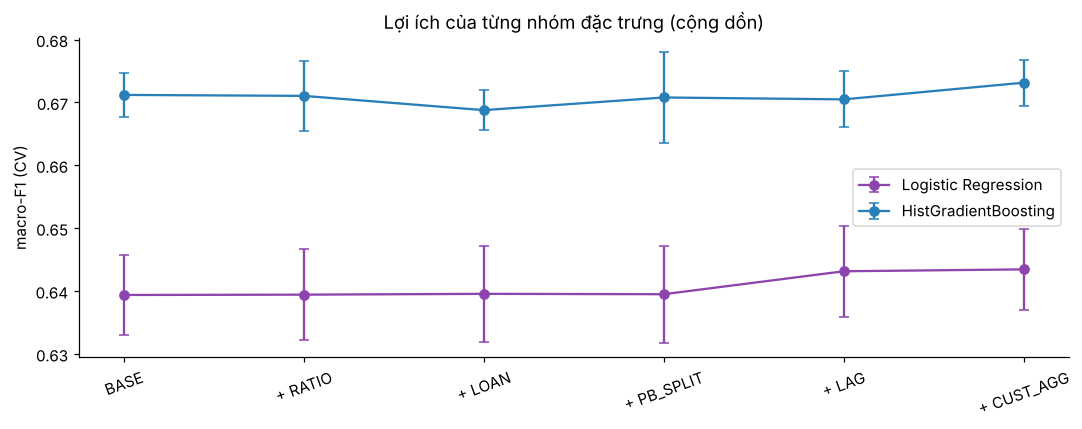

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
for m, c in [('Logistic Regression', '#8e44ad'), ('HistGradientBoosting', '#2980b9')]:
    s = fs[fs['mô hình'] == m].set_index('bộ đặc trưng').loc[list(FS)]
    ax.errorbar(range(len(FS)), s.f1, yerr=s.f1_sd, marker='o', capsize=3, label=m, color=c)
ax.set_xticks(range(len(FS))); ax.set_xticklabels([k.split('  ')[0] for k in FS], rotation=20); ax.set_ylabel('macro-F1 (CV)'); ax.legend(); ax.set_title('Lợi ích của từng nhóm đặc trưng (cộng dồn)')
plt.tight_layout(); plt.show()

In [12]:
best_causal = piv.loc['+ LAG  (nhân quả – triển khai được)']; best_retro = piv.loc['+ CUST_AGG  (nhìn lại 8 tháng)']; base_row = piv.loc['BASE']
dl = piv[['HistGradientBoosting', 'Logistic Regression']].diff().iloc[1:] * 100          # thay đổi macro-F1 (điểm %) khi thêm từng nhóm
fold_sd = pd.read_csv('../data/reports/ablation_features.csv')['f1_sd'].max() * 100
display(Markdown(f'''**Kết quả (macro-F1, CV):** HistGradientBoosting – BASE **{base_row['HistGradientBoosting']:.3f}** → thêm đặc trưng nhân quả **{best_causal['HistGradientBoosting']:.3f}** → thêm cả thống kê 8 tháng **{best_retro['HistGradientBoosting']:.3f}**.
Logistic Regression – {base_row['Logistic Regression']:.3f} → {best_causal['Logistic Regression']:.3f} → {best_retro['Logistic Regression']:.3f}.

**Nhận xét trung thực:** thêm từng nhóm đặc trưng chỉ làm macro-F1 của HistGradientBoosting thay đổi trong khoảng **{dl['HistGradientBoosting'].min():+.2f} … {dl['HistGradientBoosting'].max():+.2f}** điểm % và của Logistic Regression trong **{dl['Logistic Regression'].min():+.2f} … {dl['Logistic Regression'].max():+.2f}** điểm %, trong khi độ lệch chuẩn giữa các phần CV lên tới ≈ {fold_sd:.1f} điểm % – tức **hầu hết các thay đổi nằm trong phạm vi nhiễu**. Nhóm duy nhất có tác dụng nhìn thấy được là `LAG` đối với mô hình tuyến tính ({dl.loc['+ LAG  (nhân quả – triển khai được)', 'Logistic Regression']:+.2f} điểm %). Vì các cột gốc (đã làm sạch) đã chứa gần hết thông tin, **tạo đặc trưng đóng vai trò thứ yếu so với làm sạch** (mục 4.2).'''))

**Kết quả (macro-F1, CV):** HistGradientBoosting – BASE **0.671** → thêm đặc trưng nhân quả **0.670** → thêm cả thống kê 8 tháng **0.673**.
Logistic Regression – 0.639 → 0.643 → 0.643.

**Nhận xét trung thực:** thêm từng nhóm đặc trưng chỉ làm macro-F1 của HistGradientBoosting thay đổi trong khoảng **-0.23 … +0.27** điểm % và của Logistic Regression trong **-0.01 … +0.37** điểm %, trong khi độ lệch chuẩn giữa các phần CV lên tới ≈ 0.8 điểm % – tức **hầu hết các thay đổi nằm trong phạm vi nhiễu**. Nhóm duy nhất có tác dụng nhìn thấy được là `LAG` đối với mô hình tuyến tính (+0.37 điểm %). Vì các cột gốc (đã làm sạch) đã chứa gần hết thông tin, **tạo đặc trưng đóng vai trò thứ yếu so với làm sạch** (mục 4.2).

**Quyết định chọn bộ đặc trưng chính:** dùng bộ **`BASE + RATIO + LOAN + PB_SPLIT + LAG`** (nhân quả) làm bộ chính để báo cáo. Lý do là nguyên tắc chứ không phải vì mô hình tốt hơn rõ rệt: (1) chỉ dùng thông tin đã biết tại thời điểm dự đoán nên triển khai được trong thực tế; (2) không làm kết quả xấu đi; (3) giữ lại các đặc trưng có ý nghĩa tài chính để phân tích mức quan trọng ở mục 4.8. Bộ có thêm `CUST_AGG` (dùng cả các tháng sau) được nêu riêng như *trần "nhìn lại"* ở mục 4.10.

## 4.4 So sánh mô hình trên bộ đặc trưng chính
Cùng bộ đặc trưng, cùng các phần CV. Thêm hai đường cơ sở: đoán lớp phổ biến và cây quyết định đơn.

In [13]:
MAIN = ['BASE', 'RATIO', 'LOAN', 'PB_SPLIT', 'LAG']
X_all = cf.make_matrix(feat, MAIN); Xtr = X_all.iloc[tr_idx].reset_index(drop=True); Xte = X_all.iloc[te_idx].reset_index(drop=True)
print('Bộ đặc trưng chính:', Xtr.shape)
ALL_MODELS = {'Dummy (lớp phổ biến)': lambda: DummyClassifier(strategy='most_frequent'),
              'Decision Tree (depth 8)': lambda: DecisionTreeClassifier(max_depth=8, random_state=0), **MODELS}
mc_rows = []
for name, mk in ALL_MODELS.items():
    t = time.time(); r = cv_eval(mk, Xtr)
    mc_rows.append({'mô hình': name, 'accuracy': fmt(r[:, 0]), 'macro-F1': fmt(r[:, 1]), 'f1_mean': r[:, 1].mean(), 'thời gian (s)': round(time.time() - t)})
mc = pd.DataFrame(mc_rows).set_index('mô hình'); mc.to_csv('../data/reports/model_comparison.csv'); mc.drop(columns='f1_mean')

Bộ đặc trưng chính: (80000, 80)


,accuracy,macro-F1,thời gian (s)
mô hình,,,
Dummy (lớp phổ biến),0.532 ± 0.000,0.232 ± 0.000,1
Decision Tree (depth 8),0.700 ± 0.007,0.679 ± 0.009,7
Logistic Regression,0.667 ± 0.005,0.643 ± 0.007,32
Random Forest,0.701 ± 0.004,0.679 ± 0.003,89
HistGradientBoosting,0.696 ± 0.004,0.670 ± 0.004,59


## 4.5 Tối ưu siêu tham số
Hai mô hình mạnh nhất được tinh chỉnh bằng **tìm kiếm ngẫu nhiên** (`RandomizedSearchCV`) với CV 3 phần *theo khách* trên tập train, tối ưu macro-F1. (Không đụng tới tập kiểm tra.)

In [14]:
from scipy.stats import loguniform, randint
cv3 = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=7).split(np.zeros(len(ytr)), ytr, gtr))
search_hgb = RandomizedSearchCV(HistGradientBoostingClassifier(random_state=0), n_iter=20, cv=cv3, scoring='f1_macro', random_state=0, n_jobs=1, refit=False,
    param_distributions={'learning_rate': loguniform(0.03, 0.3), 'max_iter': randint(100, 500), 'max_leaf_nodes': randint(8, 64),
                         'min_samples_leaf': randint(10, 200), 'l2_regularization': loguniform(1e-3, 10), 'max_depth': [None, 4, 6, 8, 12]})
t = time.time(); search_hgb.fit(Xtr, ytr); print(f'HGB: {time.time() - t:.0f}s | tốt nhất macro-F1 (CV3) = {search_hgb.best_score_:.4f}')
print(search_hgb.best_params_)
res = pd.DataFrame(search_hgb.cv_results_).sort_values('rank_test_score')[['mean_test_score', 'std_test_score', 'param_learning_rate', 'param_max_iter', 'param_max_leaf_nodes', 'param_min_samples_leaf', 'param_l2_regularization', 'param_max_depth']]
res.head(6).round(4)

HGB: 827s | tốt nhất macro-F1 (CV3) = 0.6848
{'l2_regularization': np.float64(0.12387743772940756), 'learning_rate': np.float64(0.037244467166954766), 'max_depth': 4, 'max_iter': 136, 'max_leaf_nodes': 18, 'min_samples_leaf': 96}


,mean_test_score,std_test_score,param_learning_rate,param_max_iter,param_max_leaf_nodes,param_min_samples_leaf,param_l2_regularization,param_max_depth
18,0.6848,0.0004,0.0372,136,18,96,0.1239,4
13,0.6792,0.0022,0.0623,263,8,105,0.5000,4
10,0.6786,0.0018,0.0693,184,19,78,0.0183,4
3,0.6780,0.0008,0.0367,343,13,89,0.0019,8
7,0.6771,0.0008,0.0313,344,25,89,0.1878,None
17,0.6749,0.0021,0.0348,327,28,60,0.0454,6


In [15]:
search_rf = RandomizedSearchCV(RandomForestClassifier(n_jobs=2, random_state=0), n_iter=8, cv=cv3, scoring='f1_macro', random_state=0, n_jobs=1, refit=False,
    param_distributions={'n_estimators': randint(150, 400), 'max_depth': [None, 12, 20, 30], 'min_samples_leaf': randint(1, 10), 'max_features': ['sqrt', 0.3, 0.5]})
t = time.time(); search_rf.fit(Xtr, ytr); print(f'RF: {time.time() - t:.0f}s | tốt nhất macro-F1 (CV3) = {search_rf.best_score_:.4f}')
print(search_rf.best_params_)

RF: 971s | tốt nhất macro-F1 (CV3) = 0.6879
{'max_depth': 12, 'max_features': 0.3, 'min_samples_leaf': 9, 'n_estimators': 159}


In [16]:
# So sánh với mô hình mặc định trên cùng CV 5 phần
tuned = {'HistGradientBoosting (tuned)': lambda: HistGradientBoostingClassifier(random_state=0, **search_hgb.best_params_),
         'Random Forest (tuned)': lambda: RandomForestClassifier(n_jobs=2, random_state=0, **search_rf.best_params_)}
tn_rows = []
for name, mk in tuned.items():
    r = cv_eval(mk, Xtr); tn_rows.append({'mô hình': name, 'accuracy': fmt(r[:, 0]), 'macro-F1': fmt(r[:, 1]), 'f1_mean': r[:, 1].mean()})
tn = pd.DataFrame(tn_rows).set_index('mô hình')
pd.concat([mc.drop(columns='thời gian (s)'), tn]).drop(columns='f1_mean')

,accuracy,macro-F1
mô hình,,
Dummy (lớp phổ biến),0.532 ± 0.000,0.232 ± 0.000
Decision Tree (depth 8),0.700 ± 0.007,0.679 ± 0.009
Logistic Regression,0.667 ± 0.005,0.643 ± 0.007
Random Forest,0.701 ± 0.004,0.679 ± 0.003
HistGradientBoosting,0.696 ± 0.004,0.670 ± 0.004
HistGradientBoosting (tuned),0.707 ± 0.003,0.687 ± 0.003
Random Forest (tuned),0.710 ± 0.003,0.691 ± 0.003


## 4.6 Xử lý lệch lớp
Good chỉ chiếm 18%. Thử `class_weight='balanced'` (tăng trọng số lớp hiếm) trên mô hình tốt nhất và xem tác động tới **recall từng lớp**, không chỉ macro-F1.

In [17]:
best_name = max(tuned, key=lambda k: tn.loc[k, 'f1_mean']); print('Mô hình tốt nhất sau tuning (CV):', best_name)
params = search_hgb.best_params_ if 'Hist' in best_name else search_rf.best_params_
Make = (lambda **kw: HistGradientBoostingClassifier(random_state=0, **params, **kw)) if 'Hist' in best_name else (lambda **kw: RandomForestClassifier(n_jobs=2, random_state=0, **params, **kw))
rows = []
for cw in [None, 'balanced']:
    rec, f1s, accs = [], [], []
    for tr, va in folds:
        m = Make(class_weight=cw).fit(Xtr.iloc[tr], ytr.iloc[tr]); p = m.predict(Xtr.iloc[va])
        rec.append(precision_recall_fscore_support(ytr.iloc[va], p, labels=ORDER)[1]); f1s.append(f1_score(ytr.iloc[va], p, average='macro')); accs.append(accuracy_score(ytr.iloc[va], p))
    rec = np.mean(rec, axis=0); rows.append({'class_weight': str(cw), 'accuracy': np.mean(accs), 'macro-F1': np.mean(f1s), **{f'recall {k}': v for k, v in zip(ORDER, rec)}})
imb = pd.DataFrame(rows).set_index('class_weight'); imb.round(4)

Mô hình tốt nhất sau tuning (CV): Random Forest (tuned)


,accuracy,macro-F1,recall Poor,recall Standard,recall Good
class_weight,,,,,
None,0.7102,0.6907,0.6588,0.7411,0.7017
balanced,0.6862,0.6810,0.7766,0.5848,0.8429


In [18]:
CW = 'balanced' if imb.loc['balanced', 'macro-F1'] > imb.loc['None', 'macro-F1'] else None
display(Markdown(f'**Chọn `class_weight = {CW}`** (macro-F1 CV: không trọng số {imb.loc["None", "macro-F1"]:.4f}, balanced {imb.loc["balanced", "macro-F1"]:.4f}).'))

**Chọn `class_weight = None`** (macro-F1 CV: không trọng số 0.6907, balanced 0.6810).

## 4.7 Đánh giá cuối cùng trên tập kiểm tra giữ kín
Huấn luyện lại mô hình đã chọn trên **toàn bộ 80% train**, rồi chấm **một lần duy nhất** trên 2.500 khách chưa từng thấy.

In [19]:
final = Make(class_weight=CW).fit(Xtr, ytr)
pred = final.predict(Xte); proba = final.predict_proba(Xte); cls = list(final.classes_)
acc = accuracy_score(yte, pred); mf1 = f1_score(yte, pred, average='macro')
auc = roc_auc_score(yte, proba, multi_class='ovr', average='macro', labels=cls); ll = log_loss(yte, proba, labels=cls)
print(f'Accuracy {acc:.4f} | macro-F1 {mf1:.4f} | ROC-AUC (OvR, macro) {auc:.4f} | log-loss {ll:.4f}')
print(classification_report(yte, pred, labels=ORDER, digits=3))

Accuracy 0.7143 | macro-F1 0.6996 | ROC-AUC (OvR, macro) 0.8610 | log-loss 0.6486
              precision    recall  f1-score   support

        Poor      0.724     0.679     0.701      5726
    Standard      0.767     0.728     0.747     10580
        Good      0.587     0.731     0.651      3694

    accuracy                          0.714     20000
   macro avg      0.693     0.712     0.700     20000
weighted avg      0.722     0.714     0.716     20000



In [20]:
# Khoảng tin cậy 95% bằng bootstrap theo KHÁCH HÀNG (mỗi khách giữ nguyên cả 8 tháng khi lấy mẫu lại)
rng = np.random.default_rng(0); cust = gte.unique(); idx_by = {c: np.where(gte.values == c)[0] for c in cust}
bs_acc, bs_f1 = [], []
for _ in range(300):
    pick = rng.choice(cust, size=len(cust), replace=True); ii = np.concatenate([idx_by[c] for c in pick])
    bs_acc.append(accuracy_score(yte.iloc[ii], pred[ii])); bs_f1.append(f1_score(yte.iloc[ii], pred[ii], average='macro'))
ci = lambda a: f'[{np.percentile(a, 2.5):.3f}, {np.percentile(a, 97.5):.3f}]'
print('Accuracy 95% CI:', ci(bs_acc), '| macro-F1 95% CI:', ci(bs_f1))

Accuracy 95% CI: [0.702, 0.726] | macro-F1 95% CI: [0.685, 0.711]


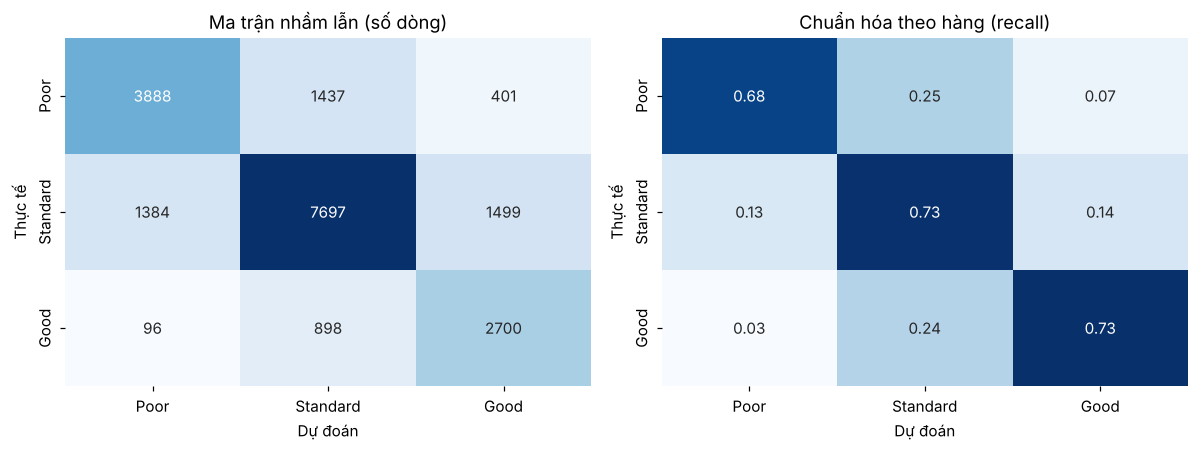

In [21]:
cm = confusion_matrix(yte, pred, labels=ORDER)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=ORDER, yticklabels=ORDER, ax=ax[0], cbar=False); ax[0].set_title('Ma trận nhầm lẫn (số dòng)')
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt='.2f', cmap='Blues', xticklabels=ORDER, yticklabels=ORDER, ax=ax[1], cbar=False); ax[1].set_title('Chuẩn hóa theo hàng (recall)')
for a in ax: a.set_xlabel('Dự đoán'); a.set_ylabel('Thực tế')
plt.tight_layout(); plt.show()

In [22]:
# Mô hình cuối so với các đường cơ sở trên CÙNG tập kiểm tra
cmp_rows = []
for name, mk, X1, X2 in [('Đoán lớp phổ biến', lambda: DummyClassifier(strategy='most_frequent'), Xtr, Xte),
                         ('Logistic Regression – dữ liệu THÔ (S0, đặc trưng gốc)', MODELS['Logistic Regression'], design(s0).iloc[tr_idx], design(s0).iloc[te_idx]),
                         ('Logistic Regression – dữ liệu SẠCH, đặc trưng gốc (S3)', MODELS['Logistic Regression'], design(clean).iloc[tr_idx], design(clean).iloc[te_idx]),
                         ('HistGradientBoosting – dữ liệu THÔ (S0, đặc trưng gốc)', MODELS['HistGradientBoosting'], design(s0).iloc[tr_idx], design(s0).iloc[te_idx]),
                         ('HistGradientBoosting – dữ liệu SẠCH, đặc trưng gốc (S3)', MODELS['HistGradientBoosting'], design(clean).iloc[tr_idx], design(clean).iloc[te_idx])]:
    p = mk().fit(X1, ytr).predict(X2); cmp_rows.append({'mô hình / dữ liệu': name, 'accuracy': accuracy_score(yte, p), 'macro-F1': f1_score(yte, p, average='macro')})
cmp_rows.append({'mô hình / dữ liệu': f'{best_name}, dữ liệu sạch + đặc trưng nhân quả (MÔ HÌNH CUỐI)', 'accuracy': acc, 'macro-F1': mf1})
final_cmp = pd.DataFrame(cmp_rows).set_index('mô hình / dữ liệu'); final_cmp.round(4)

,accuracy,macro-F1
mô hình / dữ liệu,,
Đoán lớp phổ biến,0.5290,0.2307
"Logistic Regression – dữ liệu THÔ (S0, đặc trưng gốc)",0.6169,0.5868
"Logistic Regression – dữ liệu SẠCH, đặc trưng gốc (S3)",0.6627,0.6434
"HistGradientBoosting – dữ liệu THÔ (S0, đặc trưng gốc)",0.6998,0.6778
"HistGradientBoosting – dữ liệu SẠCH, đặc trưng gốc (S3)",0.7045,0.6832
"Random Forest (tuned), dữ liệu sạch + đặc trưng nhân quả (MÔ HÌNH CUỐI)",0.7143,0.6996


In [23]:
json.dump({'model': best_name, 'params': {k: (float(v) if isinstance(v, (np.floating,)) else (int(v) if isinstance(v, (np.integer,)) else v)) for k, v in params.items()}, 'class_weight': CW,
           'accuracy': acc, 'macro_f1': mf1, 'roc_auc_ovr': auc, 'log_loss': ll, 'accuracy_ci95': [float(np.percentile(bs_acc, 2.5)), float(np.percentile(bs_acc, 97.5))],
           'macro_f1_ci95': [float(np.percentile(bs_f1, 2.5)), float(np.percentile(bs_f1, 97.5))], 'n_test_rows': int(len(yte)), 'n_test_customers': int(gte.nunique())},
          open('../data/reports/final_test_metrics.json', 'w'), ensure_ascii=False, indent=1)
final_cmp.to_csv('../data/reports/final_test_comparison.csv')
display(Markdown(f'''**Kết quả cuối (2.500 khách giữ kín):** accuracy **{acc:.3f}** (95% CI {ci(bs_acc)}), macro-F1 **{mf1:.3f}** (95% CI {ci(bs_f1)}), so với đường cơ sở {float((yte == "Standard").mean()):.3f}.'''))

**Kết quả cuối (2.500 khách giữ kín):** accuracy **0.714** (95% CI [0.702, 0.726]), macro-F1 **0.700** (95% CI [0.685, 0.711]), so với đường cơ sở 0.529.

## 4.8 Mô hình dựa vào đặc trưng nào?
**Permutation importance** (xáo trộn một đặc trưng trên tập kiểm tra rồi đo macro-F1 giảm bao nhiêu) – đáng tin hơn importance nội tại của cây vì đo trên dữ liệu chưa thấy. Đo cả theo **nhóm** đặc trưng để thấy phần nào của pipeline mang giá trị.

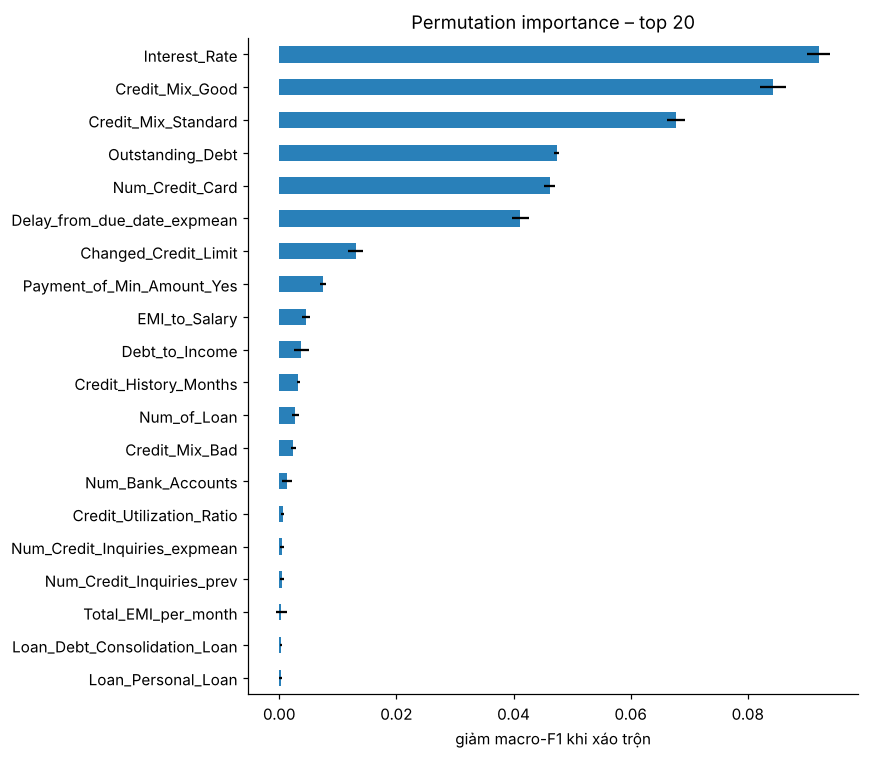

,mean,sd
Interest_Rate,0.0921,0.0020
Credit_Mix_Good,0.0843,0.0022
Credit_Mix_Standard,0.0678,0.0016
Outstanding_Debt,0.0474,0.0004
Num_Credit_Card,0.0462,0.0009
Delay_from_due_date_expmean,0.0412,0.0014
Changed_Credit_Limit,0.0130,0.0013
Payment_of_Min_Amount_Yes,0.0075,0.0005
EMI_to_Salary,0.0045,0.0007
Debt_to_Income,0.0038,0.0013


In [24]:
def macro_f1_score(est, X, y): return f1_score(y, est.predict(X), average='macro')
samp = np.random.default_rng(1).choice(len(Xte), size=min(12000, len(Xte)), replace=False)
pi = permutation_importance(final, Xte.iloc[samp], yte.iloc[samp], scoring=macro_f1_score, n_repeats=3, random_state=0, n_jobs=1)
imp = pd.DataFrame({'mean': pi.importances_mean, 'sd': pi.importances_std}, index=Xte.columns).sort_values('mean', ascending=False)
fig, ax = plt.subplots(figsize=(8, 7)); imp.head(20)[::-1]['mean'].plot(kind='barh', xerr=imp.head(20)[::-1]['sd'], ax=ax, color='#2980b9'); ax.set_xlabel('giảm macro-F1 khi xáo trộn'); ax.set_title('Permutation importance – top 20')
plt.tight_layout(); plt.show()
imp.head(12).round(4)

In [25]:
# Theo nhóm: xáo trộn đồng thời mọi cột của nhóm (mỗi cột của ma trận one-hot được gán về nhóm gốc của nó)
def col_group(c):
    for g, feats in cf.FEATURE_GROUPS.items():
        for f in feats:
            if c == f or (f in cf.CATEGORICAL and c.startswith(f + '_')): return g
    return '?'
col2grp = pd.Series({c: col_group(c) for c in Xte.columns}); assert (col2grp != '?').all()
rng = np.random.default_rng(2); Xs, ys = Xte.iloc[samp].reset_index(drop=True), yte.iloc[samp].reset_index(drop=True)
base_f1 = f1_score(ys, final.predict(Xs), average='macro'); rows = []
for g in ['BASE', 'RATIO', 'LOAN', 'PB_SPLIT', 'LAG']:
    cols = list(col2grp.index[col2grp == g]); drops = []
    for _ in range(3):
        Xp = Xs.copy(); perm = rng.permutation(len(Xs)); Xp[cols] = Xs[cols].values[perm]; drops.append(base_f1 - f1_score(ys, final.predict(Xp), average='macro'))
    rows.append({'nhóm': g, 'số cột': len(cols), 'macro-F1 giảm khi xáo trộn cả nhóm': np.mean(drops)})
grp_imp = pd.DataFrame(rows).set_index('nhóm'); grp_imp.round(4)

,số cột,macro-F1 giảm khi xáo trộn cả nhóm
nhóm,,
BASE,45,0.3544
RATIO,7,0.0065
LOAN,9,-0.0005
PB_SPLIT,7,-0.0003
LAG,12,0.0437


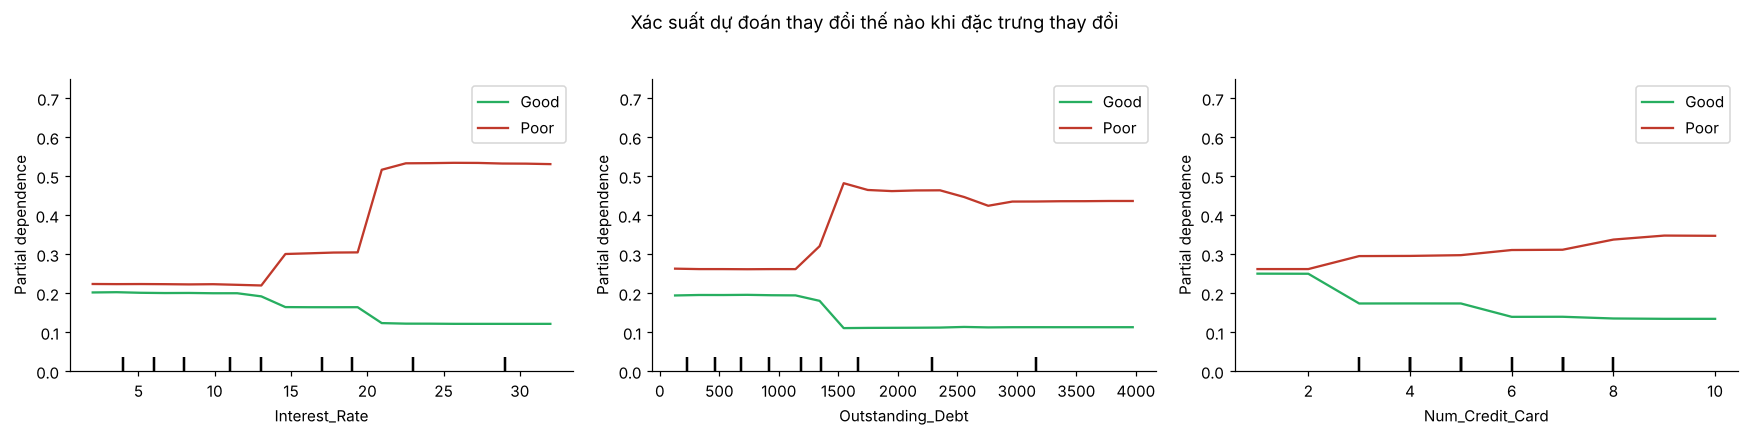

In [26]:
# Đồ thị phụ thuộc riêng phần (PDP) cho 3 đặc trưng quan trọng nhất – lớp Good và Poor
dummy_prefix = tuple(c + '_' for c in cf.CATEGORICAL)
top3 = [c for c in imp.index if not c.startswith(dummy_prefix)][:3]      # chỉ đặc trưng số (cột one-hot không vẽ PDP có ý nghĩa)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for tgt, col in [('Good', PAL['Good']), ('Poor', PAL['Poor'])]:
    PartialDependenceDisplay.from_estimator(final, Xte.iloc[samp[:3000]], top3, target=tgt, ax=ax, method='brute', response_method='predict_proba', line_kw={'color': col, 'label': tgt}, grid_resolution=20)
for a in ax: a.set_ylim(0, 0.75)
ax[0].legend(); plt.suptitle('Xác suất dự đoán thay đổi thế nào khi đặc trưng thay đổi', y=1.03); plt.tight_layout(); plt.show()

In [27]:
top_feats = [f'`{c}` ({v:.3f})' for c, v in imp['mean'].head(6).items()]
gi = grp_imp['macro-F1 giảm khi xáo trộn cả nhóm']
negl = [k for k in gi.index if gi[k] < 0.01]
display(Markdown(f'''**Đọc kết quả.**
- **6 đặc trưng quan trọng nhất** (macro-F1 giảm khi xáo trộn, trên tập kiểm tra): {', '.join(top_feats)}. Đây đều là chỉ số **nợ / thanh toán / hạng mục tín dụng** – hợp lý về mặt tài chính và khớp với các cột có hiệu ứng lớn nhất ở EDA (mục 1.7). Các cột định danh hay tháng (`Month_Num`, `Occupation`…) không đứng đầu danh sách. (Lưu ý: cột one-hot được xáo trộn **riêng từng cột**, nên tầm quan trọng của `Credit_Mix` nói chung lớn hơn con số của từng cột `Credit_Mix_*`.)
- **Theo nhóm:** `BASE` (cột gốc đã làm sạch) mang gần như toàn bộ tín hiệu (giảm {gi['BASE']:.3f}); `LAG` giảm {gi['LAG']:.3f}; các nhóm {', '.join('`' + k + '`' for k in negl)} đóng góp dưới 0,01 – khớp với ablation ở 4.3: đặc trưng tự tạo không thêm nhiều thông tin so với cột gốc. (`LAG` quan trọng khi xáo trộn nhưng bỏ đi gần như không làm giảm điểm vì nó **thay thế được** bởi các cột gốc tương quan cao với nó.)
- Đồ thị phụ thuộc riêng phần (PDP) ở trên vẽ xác suất dự đoán lớp Good và Poor theo từng đặc trưng số hàng đầu; hướng của đường cong cho thấy mô hình có hợp lý về mặt tài chính không (ví dụ lãi suất cao thì xác suất Poor tăng, Good giảm).'''))

**Đọc kết quả.**
- **6 đặc trưng quan trọng nhất** (macro-F1 giảm khi xáo trộn, trên tập kiểm tra): `Interest_Rate` (0.092), `Credit_Mix_Good` (0.084), `Credit_Mix_Standard` (0.068), `Outstanding_Debt` (0.047), `Num_Credit_Card` (0.046), `Delay_from_due_date_expmean` (0.041). Đây đều là chỉ số **nợ / thanh toán / hạng mục tín dụng** – hợp lý về mặt tài chính và khớp với các cột có hiệu ứng lớn nhất ở EDA (mục 1.7). Các cột định danh hay tháng (`Month_Num`, `Occupation`…) không đứng đầu danh sách. (Lưu ý: cột one-hot được xáo trộn **riêng từng cột**, nên tầm quan trọng của `Credit_Mix` nói chung lớn hơn con số của từng cột `Credit_Mix_*`.)
- **Theo nhóm:** `BASE` (cột gốc đã làm sạch) mang gần như toàn bộ tín hiệu (giảm 0.354); `LAG` giảm 0.044; các nhóm `RATIO`, `LOAN`, `PB_SPLIT` đóng góp dưới 0,01 – khớp với ablation ở 4.3: đặc trưng tự tạo không thêm nhiều thông tin so với cột gốc. (`LAG` quan trọng khi xáo trộn nhưng bỏ đi gần như không làm giảm điểm vì nó **thay thế được** bởi các cột gốc tương quan cao với nó.)
- Đồ thị phụ thuộc riêng phần (PDP) ở trên vẽ xác suất dự đoán lớp Good và Poor theo từng đặc trưng số hàng đầu; hướng của đường cong cho thấy mô hình có hợp lý về mặt tài chính không (ví dụ lãi suất cao thì xác suất Poor tăng, Good giảm).

## 4.9 Phân tích lỗi: mô hình sai ở đâu?
Mô hình có thể giỏi trung bình nhưng sai có hệ thống ở một số nhóm. Xem xét theo (a) tháng, (b) mức `Credit_Mix`, (c) **dòng mà nhãn vừa đổi so với tháng trước** (các điểm chuyển nhãn).

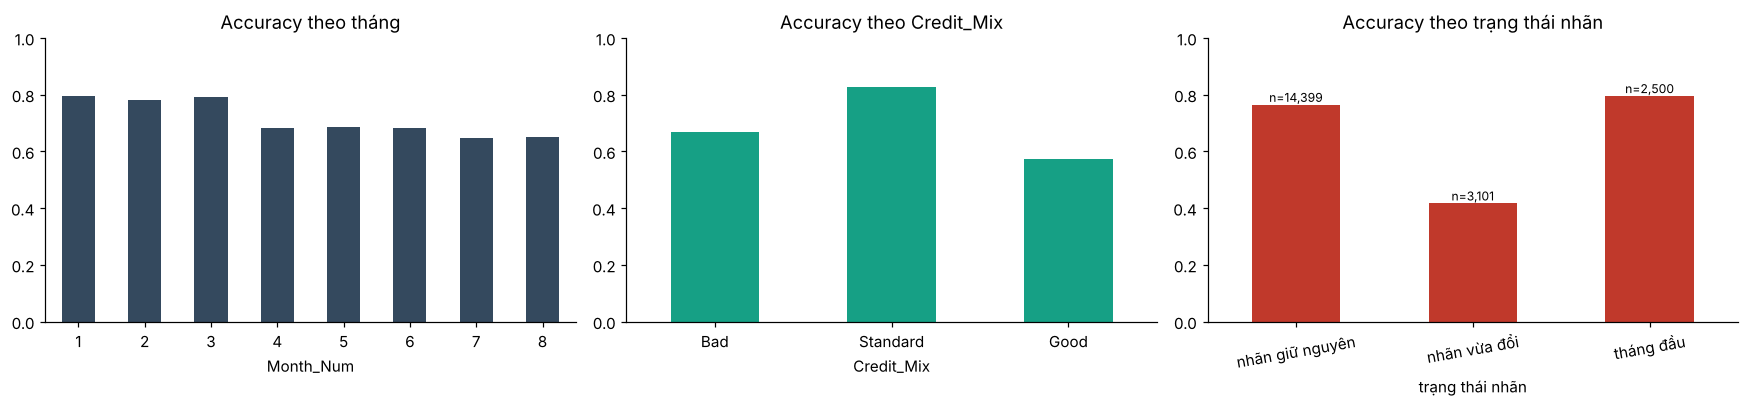

,mean,size
trạng thái nhãn,,
nhãn giữ nguyên,0.764,14399
nhãn vừa đổi,0.417,3101
tháng đầu,0.795,2500


In [28]:
te = clean.iloc[te_idx].reset_index(drop=True).assign(pred=pred, correct=(pred == yte.values))
te['prev_label'] = te.groupby('Customer_ID')['Credit_Score'].shift(1)
te['trạng thái nhãn'] = np.where(te.prev_label.isna(), 'tháng đầu', np.where(te.prev_label == te.Credit_Score, 'nhãn giữ nguyên', 'nhãn vừa đổi'))
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
te.groupby('Month_Num').correct.mean().plot(kind='bar', ax=ax[0], color='#34495e', rot=0); ax[0].set_ylim(0, 1); ax[0].set_title('Accuracy theo tháng')
te.groupby('Credit_Mix').correct.mean().reindex(['Bad', 'Standard', 'Good']).plot(kind='bar', ax=ax[1], color='#16a085', rot=0); ax[1].set_ylim(0, 1); ax[1].set_title('Accuracy theo Credit_Mix')
tt = te.groupby('trạng thái nhãn').correct.agg(['mean', 'size']); tt['mean'].plot(kind='bar', ax=ax[2], color='#c0392b', rot=10); ax[2].set_ylim(0, 1); ax[2].set_title('Accuracy theo trạng thái nhãn')
for i, (m, n) in enumerate(zip(tt['mean'], tt['size'])): ax[2].text(i, m, f'n={n:,}', ha='center', va='bottom', fontsize=8)
plt.tight_layout(); plt.show()
tt.round(3)

In [29]:
# Accuracy theo tháng đặt cạnh tỷ lệ nhãn đổi so với tháng trước (tính trên toàn bộ dữ liệu), và accuracy theo Credit_Mix
_c = clean.assign(prev=clean.groupby('Customer_ID')['Credit_Score'].shift(1))
chg_rate = (_c.prev.notna() & (_c.prev != _c.Credit_Score)).groupby(_c.Month_Num).mean()
mon = te.groupby('Month_Num').correct.agg(['mean', 'size']).rename(columns={'mean': 'accuracy (tập kiểm tra)', 'size': 'số dòng'})
mon['tỷ lệ nhãn đổi so với tháng trước (toàn bộ dữ liệu)'] = chg_rate.round(3)
display(mon.round(3).T)
mix = te.groupby('Credit_Mix').correct.agg(['mean', 'size']).reindex(['Bad', 'Standard', 'Good']).rename(columns={'mean': 'accuracy', 'size': 'số dòng'})
display(mix.round(3).T)

Month_Num,1,2,3,4,5,6,7,8
accuracy (tập kiểm tra),0.795,0.780,0.792,0.684,0.685,0.683,0.646,0.649
số dòng,2500.000,2500.000,2500.000,2500.000,2500.000,2500.000,2500.000,2500.000
tỷ lệ nhãn đổi so với tháng trước (toàn bộ dữ liệu),0.000,0.129,0.131,0.256,0.146,0.143,0.273,0.145


Credit_Mix,Bad,Standard,Good
accuracy,0.67,0.828,0.571
số dòng,4744.00,9320.000,5936.000


In [30]:
# Mô hình tự tin đến đâu và có hiệu chỉnh tốt không? (độ tin cậy = xác suất lớp dự đoán)
conf = proba.max(axis=1); te['conf'] = conf
bins = pd.cut(conf, [0, .5, .6, .7, .8, .9, 1.0]); rel = te.groupby(bins).agg(n=('correct', 'size'), accuracy=('correct', 'mean'), độ_tin_cậy_TB=('conf', 'mean')).round(3); rel

,n,accuracy,độ_tin_cậy_TB
"(0.0, 0.5]",2968,0.477,0.468
"(0.5, 0.6]",3570,0.546,0.541
"(0.6, 0.7]",1772,0.675,0.647
"(0.7, 0.8]",4320,0.769,0.760
"(0.8, 0.9]",5850,0.852,0.858
"(0.9, 1.0]",1520,0.934,0.913


In [31]:
# Các nhầm lẫn: lớp nào bị nhầm sang lớp nào, kèm số dòng
conf_pairs = te[~te.correct].groupby(['Credit_Score', 'pred']).size().rename('số dòng sai').reset_index().sort_values('số dòng sai', ascending=False)
conf_pairs['% tổng lỗi'] = (conf_pairs['số dòng sai'] / (~te.correct).sum() * 100).round(1); conf_pairs.rename(columns={'Credit_Score': 'thực tế', 'pred': 'dự đoán'})

,thực tế,dự đoán,số dòng sai,% tổng lỗi
4,Standard,Good,1499,26.2
3,Poor,Standard,1437,25.1
5,Standard,Poor,1384,24.2
1,Good,Standard,898,15.7
2,Poor,Good,401,7.0
0,Good,Poor,96,1.7


In [32]:
# Dòng bị sửa nhiều có bị đoán sai nhiều hơn không? (làm sạch có để lại "vết" ảnh hưởng tới mô hình không)
d3_ = cc.mark_invalid(cc.strip_numeric_text(cc.mark_placeholders(cc.add_month_num(raw))))
n_fixed = d3_.drop(columns=['Type_of_Loan', 'Credit_Score']).isna().sum(axis=1).values[te_idx]
te['số ô phải sửa'] = pd.cut(n_fixed, [-1, 0, 1, 2, 99], labels=['0', '1', '2', '≥3'])
te['Monthly_Balance bị điền'] = d3_['Monthly_Balance'].isna().values[te_idx]
by_fix = te.groupby('số ô phải sửa', observed=True).correct.agg(['mean', 'size']).round(3).rename(columns={'mean': 'accuracy', 'size': 'số dòng'})
by_mb = te.groupby('Monthly_Balance bị điền').correct.agg(['mean', 'size']).round(3).rename(columns={'mean': 'accuracy', 'size': 'số dòng'})
display(by_fix); display(by_mb)

,accuracy,số dòng
số ô phải sửa,,
0,0.720,5865
1,0.715,7661
2,0.712,4515
≥3,0.699,1959


,accuracy,số dòng
Monthly_Balance bị điền,,
False,0.714,19772
True,0.702,228


In [33]:
pg_share = conf_pairs[conf_pairs.Credit_Score.isin(['Poor', 'Good']) & conf_pairs.pred.isin(['Poor', 'Good'])]['% tổng lỗi'].sum()
e_state = te.groupby('trạng thái nhãn').correct.mean(); share_err = te[~te.correct]['trạng thái nhãn'].value_counts(normalize=True)
mx = te.groupby('Month_Num').correct.mean()
display(Markdown(f'''**Phát hiện từ phân tích lỗi:**
- Accuracy ở các dòng **nhãn giữ nguyên**: {e_state.get('nhãn giữ nguyên', float('nan')):.3f}; ở các dòng **nhãn vừa đổi**: {e_state.get('nhãn vừa đổi', float('nan')):.3f}. Các dòng nhãn vừa đổi chiếm {share_err.get('nhãn vừa đổi', 0):.0%} số lỗi dù chỉ là một phần nhỏ dữ liệu – mô hình khó bắt đúng *thời điểm chuyển nhãn*.
- Accuracy theo tháng: {te[te.Month_Num <= 3].correct.mean():.3f} ở tháng 1–3 nhưng chỉ {te[te.Month_Num >= 4].correct.mean():.3f} ở tháng 4–8 (thấp nhất {mx.min():.3f} ở tháng {int(mx.idxmin())}, cao nhất {mx.max():.3f} ở tháng {int(mx.idxmax())}). Tỷ lệ nhãn đổi so với tháng trước nhảy lên {chg_rate.loc[4]:.0%} (tháng 4) và {chg_rate.loc[7]:.0%} (tháng 7), so với {chg_rate.loc[[2, 3, 5, 6, 8]].min():.0%}–{chg_rate.loc[[2, 3, 5, 6, 8]].max():.0%} ở các tháng còn lại; điều này khớp với việc accuracy tụt ở tháng 4 và 7 nhưng **không giải thích hết** (các tháng 5, 6, 8 cũng thấp hơn tháng 2–3 dù tỷ lệ nhãn đổi tương đương). Nguyên nhân phần còn lại chưa xác định – có thể là đặc điểm của cách dữ liệu tổng hợp được tạo ra (phân phối nhãn cũng dịch chuyển từ tháng 4: Good từ ≈16% lên ≈19%).
- Theo số ô phải sửa trong dòng: accuracy {by_fix['accuracy'].iloc[0]:.3f} (dòng không phải sửa ô nào) → {by_fix['accuracy'].iloc[-1]:.3f} (dòng ≥ 3 ô); riêng các dòng có `Monthly_Balance` phải điền: {by_mb['accuracy'].get(True, float('nan')):.3f} (so với {by_mb['accuracy'].get(False, float('nan')):.3f} khi còn nguyên) – xem có chênh lệch đáng kể hay không.
- Nhầm lẫn trực tiếp **Poor ↔ Good chỉ chiếm {pg_share:.1f}%** số lỗi; {100 - pg_share:.1f}% còn lại là nhầm với lớp giữa **Standard** (ranh giới mờ giữa các mức), xem ma trận nhầm lẫn.'''))

**Phát hiện từ phân tích lỗi:**
- Accuracy ở các dòng **nhãn giữ nguyên**: 0.764; ở các dòng **nhãn vừa đổi**: 0.417. Các dòng nhãn vừa đổi chiếm 32% số lỗi dù chỉ là một phần nhỏ dữ liệu – mô hình khó bắt đúng *thời điểm chuyển nhãn*.
- Accuracy theo tháng: 0.789 ở tháng 1–3 nhưng chỉ 0.670 ở tháng 4–8 (thấp nhất 0.646 ở tháng 7, cao nhất 0.795 ở tháng 1). Tỷ lệ nhãn đổi so với tháng trước nhảy lên 26% (tháng 4) và 27% (tháng 7), so với 13%–15% ở các tháng còn lại; điều này khớp với việc accuracy tụt ở tháng 4 và 7 nhưng **không giải thích hết** (các tháng 5, 6, 8 cũng thấp hơn tháng 2–3 dù tỷ lệ nhãn đổi tương đương). Nguyên nhân phần còn lại chưa xác định – có thể là đặc điểm của cách dữ liệu tổng hợp được tạo ra (phân phối nhãn cũng dịch chuyển từ tháng 4: Good từ ≈16% lên ≈19%).
- Theo số ô phải sửa trong dòng: accuracy 0.720 (dòng không phải sửa ô nào) → 0.699 (dòng ≥ 3 ô); riêng các dòng có `Monthly_Balance` phải điền: 0.702 (so với 0.714 khi còn nguyên) – xem có chênh lệch đáng kể hay không.
- Nhầm lẫn trực tiếp **Poor ↔ Good chỉ chiếm 8.7%** số lỗi; 91.3% còn lại là nhầm với lớp giữa **Standard** (ranh giới mờ giữa các mức), xem ma trận nhầm lẫn.

## 4.10 Trần "nhìn lại": nếu có đủ 8 tháng
Bộ chính (nhân quả) là con số có thể triển khai. Để biết thêm thông tin 8 tháng giúp được bao nhiêu, đánh giá bộ `+ CUST_AGG` trên cùng tập kiểm tra (**chỉ để tham khảo, không dùng làm kết quả chính**).

In [34]:
Xr = cf.make_matrix(feat, MAIN + ['CUST_AGG']); retro = Make(class_weight=CW).fit(Xr.iloc[tr_idx], ytr); pr = retro.predict(Xr.iloc[te_idx])
acc_r, f1_r = accuracy_score(yte, pr), f1_score(yte, pr, average='macro')
display(Markdown(f'''| Bộ đặc trưng | accuracy | macro-F1 |
|---|---|---|
| Nhân quả (kết quả chính) | {acc:.3f} | {mf1:.3f} |
| Nhìn lại 8 tháng (+ CUST_AGG, trần tham khảo) | {acc_r:.3f} | {f1_r:.3f} |'''))

| Bộ đặc trưng | accuracy | macro-F1 |
|---|---|---|
| Nhân quả (kết quả chính) | 0.714 | 0.700 |
| Nhìn lại 8 tháng (+ CUST_AGG, trần tham khảo) | 0.716 | 0.702 |

In [35]:
g = abl.set_index(['mô hình', 'giai đoạn'])
fc = final_cmp['macro-F1']; fa = final_cmp['accuracy']
k_lr = fc['Logistic Regression – dữ liệu SẠCH, đặc trưng gốc (S3)'] - fc['Logistic Regression – dữ liệu THÔ (S0, đặc trưng gốc)']
k_hg = fc['HistGradientBoosting – dữ liệu SẠCH, đặc trưng gốc (S3)'] - fc['HistGradientBoosting – dữ liệu THÔ (S0, đặc trưng gốc)']
k_rest = mf1 - fc['HistGradientBoosting – dữ liệu SẠCH, đặc trưng gốc (S3)']
n_chg = int((te['trạng thái nhãn'] == 'nhãn vừa đổi').sum()); n_prev = int((te['trạng thái nhãn'] != 'tháng đầu').sum())
n_mb = int(te['Monthly_Balance bị điền'].sum()); p_mb = float(te.loc[~te['Monthly_Balance bị điền'], 'correct'].mean()); se_mb = (p_mb * (1 - p_mb) / max(n_mb, 1)) ** 0.5
gap_mb = float(te.loc[te['Monthly_Balance bị điền'], 'correct'].mean()) - p_mb
p0, p3, n0, n3 = by_fix['accuracy'].iloc[0], by_fix['accuracy'].iloc[-1], by_fix['số dòng'].iloc[0], by_fix['số dòng'].iloc[-1]
d_fix = p3 - p0; z_fix = d_fix / ((p0 * (1 - p0) / n0 + p3 * (1 - p3) / n3) ** 0.5)
display(Markdown(f'''## Kết luận

**1. Làm sạch có giá trị đo được – nhưng độ lớn phụ thuộc mô hình.** Trên cùng đặc trưng và mô hình, từ dữ liệu thô (S0) tới làm sạch đầy đủ (S3), macro-F1 (CV 5 phần theo khách) tăng **{paired.loc[('Logistic Regression', 'S3 − S0'), 'Δ macro-F1 TB (điểm %)']:+.1f}** điểm % với Logistic Regression ({paired.loc[('Logistic Regression', 'S3 − S0'), 'số phần cải thiện']} phần CV cải thiện), **{paired.loc[('Random Forest', 'S3 − S0'), 'Δ macro-F1 TB (điểm %)']:+.1f}** với Random Forest ({paired.loc[('Random Forest', 'S3 − S0'), 'số phần cải thiện']}) và **{paired.loc[(hgb, 'S3 − S0'), 'Δ macro-F1 TB (điểm %)']:+.1f}** với HistGradientBoosting ({paired.loc[(hgb, 'S3 − S0'), 'số phần cải thiện']}). Trên tập kiểm tra giữ kín: {k_lr * 100:+.1f} điểm % (Logistic Regression) và {k_hg * 100:+.1f} điểm % (HistGradientBoosting). Mô hình tuyến tính được lợi nhiều nhất vì bị phá bởi ngoại lệ; mô hình cây vốn chịu được ngoại lệ nên lợi ích nhỏ hơn.

**2. Phải là làm sạch "có hiểu biết", không phải "máy móc".** Với mô hình cây, chỉ bỏ placeholder / giá trị vô lý rồi điền trung vị toàn cục (S1, S2) không hơn dữ liệu thô, và để mô hình tự xử lý NaN (`S2*`) cũng không giúp; lợi ích chỉ xuất hiện khi điền theo từng khách và theo ràng buộc giữa các cột (S3 hơn `S2*` {star_gap:+.1f} điểm %).

**3. Kết quả cuối** (2.500 khách giữ kín, chưa từng dùng để chọn gì): accuracy **{acc:.3f}** (95% CI {ci(bs_acc)}), macro-F1 **{mf1:.3f}** (95% CI {ci(bs_f1)}), ROC-AUC **{auc:.3f}**; đường cơ sở (luôn đoán Standard) accuracy {float((yte == "Standard").mean()):.3f}. So với HistGradientBoosting mặc định trên dữ liệu thô, mô hình cuối hơn {(mf1 - fc['HistGradientBoosting – dữ liệu THÔ (S0, đặc trưng gốc)']) * 100:+.1f} điểm % macro-F1, trong đó {k_hg * 100:+.1f} điểm % là nhờ làm sạch và {k_rest * 100:+.1f} điểm % nhờ chọn mô hình / tối ưu siêu tham số / đặc trưng.

**4. Tạo đặc trưng chỉ đóng vai trò thứ yếu.** Các nhóm đặc trưng tự tạo gần như không cải thiện mô hình (mục 4.3), và bộ đặc trưng "nhìn lại 8 tháng" chỉ hơn bộ nhân quả {(f1_r - mf1) * 100:+.1f} điểm % macro-F1 trên tập kiểm tra ({acc_r:.3f} so với {acc:.3f} accuracy).

**5. Mô hình sai ở đâu.** (a) Ở các tháng **nhãn vừa đổi** so với tháng trước (chiếm {n_chg / n_prev:.0%} số dòng nhưng {share_err.get('nhãn vừa đổi', 0):.0%} số lỗi), accuracy chỉ {e_state.get('nhãn vừa đổi', float('nan')):.2f} so với {e_state.get('nhãn giữ nguyên', float('nan')):.2f} khi nhãn giữ nguyên. (b) Nhầm lẫn trực tiếp Poor ↔ Good chỉ chiếm {pg_share:.1f}% số lỗi; còn lại là ranh giới với Standard. (c) Dòng càng phải sửa nhiều ô thì accuracy giảm nhẹ ({by_fix['accuracy'].iloc[0]:.3f} → {by_fix['accuracy'].iloc[-1]:.3f} từ 0 tới ≥ 3 ô sửa, chênh {d_fix * 100:+.1f} điểm %, z ≈ {z_fix:.1f}) – chiều này phù hợp với việc giá trị được điền chỉ là ước lượng chứ không phải số thật, nhưng mức giảm nhỏ và **chưa đạt ý nghĩa thống kê** (|z| < 2) nên chỉ là gợi ý; với {n_mb} dòng có `Monthly_Balance` phải điền, chênh lệch {gap_mb * 100:+.1f} điểm % nằm trong sai số chuẩn ≈ {se_mb * 100:.1f} điểm % nên **không kết luận được** là có ảnh hưởng.

### Hạn chế
- **Dữ liệu tổng hợp (Kaggle):** nhãn có nhiều nhiễu theo tháng (EDA 1.2; phần trên cho thấy ngay cả khi biết trước cả 8 tháng của khách thì kết quả cũng hầu như không tăng), nên các mô hình rất khác nhau (cây đơn, rừng ngẫu nhiên, boosting) đều dừng quanh 0,70–0,72 accuracy. Điều đáng tin ở bài này là **chênh lệch giữa các giai đoạn làm sạch trong cùng điều kiện**, không phải con số tuyệt đối – không nên suy ra hiệu năng trên dữ liệu ngân hàng thật.
- Thí nghiệm chọn chiến lược điền "che 10%" giả định ô thiếu thật xuất hiện ngẫu nhiên; với `Monthly_Balance` có dấu hiệu thiếu không ngẫu nhiên (notebook 3, mục 3.1) nên sai số thật ở nhóm đó không đo được. `Amount_invested_monthly`, `Monthly_Balance` là giá trị ước lượng.
- Làm sạch (trung vị toàn cục, mô hình điền thiếu) được tính trên toàn bộ 100.000 dòng *không dùng nhãn* trước khi chia train/test – không rò rỉ nhãn, nhưng về nguyên tắc nếu triển khai thật cần học các tham số này chỉ từ dữ liệu huấn luyện.
- Một lần chia train/test (hạt ngẫu nhiên cố định); khoảng tin cậy bootstrap phản ánh dao động do mẫu kiểm tra, không phản ánh dao động do cách chia.
- Tối ưu siêu tham số bằng tìm kiếm ngẫu nhiên (CV 3 phần, 20 và 8 cấu hình) – chưa tối ưu tới cùng. Chưa dùng `test.csv` (không có nhãn); có thể áp dụng `clean()` + mô hình cuối để dự đoán.'''))
print(f'Tổng thời gian chạy notebook: {(time.time() - T0) / 60:.1f} phút')

## Kết luận

**1. Làm sạch có giá trị đo được – nhưng độ lớn phụ thuộc mô hình.** Trên cùng đặc trưng và mô hình, từ dữ liệu thô (S0) tới làm sạch đầy đủ (S3), macro-F1 (CV 5 phần theo khách) tăng **+5.1** điểm % với Logistic Regression (5/5 phần CV cải thiện), **+1.0** với Random Forest (5/5) và **+0.9** với HistGradientBoosting (5/5). Trên tập kiểm tra giữ kín: +5.7 điểm % (Logistic Regression) và +0.5 điểm % (HistGradientBoosting). Mô hình tuyến tính được lợi nhiều nhất vì bị phá bởi ngoại lệ; mô hình cây vốn chịu được ngoại lệ nên lợi ích nhỏ hơn.

**2. Phải là làm sạch "có hiểu biết", không phải "máy móc".** Với mô hình cây, chỉ bỏ placeholder / giá trị vô lý rồi điền trung vị toàn cục (S1, S2) không hơn dữ liệu thô, và để mô hình tự xử lý NaN (`S2*`) cũng không giúp; lợi ích chỉ xuất hiện khi điền theo từng khách và theo ràng buộc giữa các cột (S3 hơn `S2*` +0.8 điểm %).

**3. Kết quả cuối** (2.500 khách giữ kín, chưa từng dùng để chọn gì): accuracy **0.714** (95% CI [0.702, 0.726]), macro-F1 **0.700** (95% CI [0.685, 0.711]), ROC-AUC **0.861**; đường cơ sở (luôn đoán Standard) accuracy 0.529. So với HistGradientBoosting mặc định trên dữ liệu thô, mô hình cuối hơn +2.2 điểm % macro-F1, trong đó +0.5 điểm % là nhờ làm sạch và +1.6 điểm % nhờ chọn mô hình / tối ưu siêu tham số / đặc trưng.

**4. Tạo đặc trưng chỉ đóng vai trò thứ yếu.** Các nhóm đặc trưng tự tạo gần như không cải thiện mô hình (mục 4.3), và bộ đặc trưng "nhìn lại 8 tháng" chỉ hơn bộ nhân quả +0.3 điểm % macro-F1 trên tập kiểm tra (0.716 so với 0.714 accuracy).

**5. Mô hình sai ở đâu.** (a) Ở các tháng **nhãn vừa đổi** so với tháng trước (chiếm 18% số dòng nhưng 32% số lỗi), accuracy chỉ 0.42 so với 0.76 khi nhãn giữ nguyên. (b) Nhầm lẫn trực tiếp Poor ↔ Good chỉ chiếm 8.7% số lỗi; còn lại là ranh giới với Standard. (c) Dòng càng phải sửa nhiều ô thì accuracy giảm nhẹ (0.720 → 0.699 từ 0 tới ≥ 3 ô sửa, chênh -2.1 điểm %, z ≈ -1.8) – chiều này phù hợp với việc giá trị được điền chỉ là ước lượng chứ không phải số thật, nhưng mức giảm nhỏ và **chưa đạt ý nghĩa thống kê** (|z| < 2) nên chỉ là gợi ý; với 228 dòng có `Monthly_Balance` phải điền, chênh lệch -1.3 điểm % nằm trong sai số chuẩn ≈ 3.0 điểm % nên **không kết luận được** là có ảnh hưởng.

### Hạn chế
- **Dữ liệu tổng hợp (Kaggle):** nhãn có nhiều nhiễu theo tháng (EDA 1.2; phần trên cho thấy ngay cả khi biết trước cả 8 tháng của khách thì kết quả cũng hầu như không tăng), nên các mô hình rất khác nhau (cây đơn, rừng ngẫu nhiên, boosting) đều dừng quanh 0,70–0,72 accuracy. Điều đáng tin ở bài này là **chênh lệch giữa các giai đoạn làm sạch trong cùng điều kiện**, không phải con số tuyệt đối – không nên suy ra hiệu năng trên dữ liệu ngân hàng thật.
- Thí nghiệm chọn chiến lược điền "che 10%" giả định ô thiếu thật xuất hiện ngẫu nhiên; với `Monthly_Balance` có dấu hiệu thiếu không ngẫu nhiên (notebook 3, mục 3.1) nên sai số thật ở nhóm đó không đo được. `Amount_invested_monthly`, `Monthly_Balance` là giá trị ước lượng.
- Làm sạch (trung vị toàn cục, mô hình điền thiếu) được tính trên toàn bộ 100.000 dòng *không dùng nhãn* trước khi chia train/test – không rò rỉ nhãn, nhưng về nguyên tắc nếu triển khai thật cần học các tham số này chỉ từ dữ liệu huấn luyện.
- Một lần chia train/test (hạt ngẫu nhiên cố định); khoảng tin cậy bootstrap phản ánh dao động do mẫu kiểm tra, không phản ánh dao động do cách chia.
- Tối ưu siêu tham số bằng tìm kiếm ngẫu nhiên (CV 3 phần, 20 và 8 cấu hình) – chưa tối ưu tới cùng. Chưa dùng `test.csv` (không có nhãn); có thể áp dụng `clean()` + mô hình cuối để dự đoán.

Tổng thời gian chạy notebook: 59.7 phút
